# Practical 4 — Gradient Descent to Find a Local Minimum

**Subject:** Machine Learning (410242)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Implement the Gradient Descent algorithm to find the local minimum of a
function. Use the example

$$y=(x+3)^2$$

starting from $x=2$, and study the effect of the learning rate and the initial
point.

## 2. Problem statement

Minimise

$$f(x)=(x+3)^2.$$

The gradient is

$$f'(x)=2(x+3).$$

Starting at $x_0=2$, repeatedly apply

$$x_{t+1}=x_t-\eta f'(x_t),$$

where $\eta$ is the learning rate. Stop when the change in $x$ is below a
tolerance, and report the minimiser, the minimum value and the number of
iterations.

## 3. Objectives

- Understand the gradient-descent update rule.
- See how the learning rate affects convergence, oscillation and divergence.
- Verify the result analytically.
- Understand why different starting points can matter for non-convex
  functions.

## 4. Theory

### 4.1 The update rule

The gradient points in the direction of steepest **increase**. To minimise,
move in the opposite direction:

$$x_{t+1}=x_t-\eta\nabla f(x_t).$$

For a one-dimensional function, $\nabla f(x)=f'(x)$. The learning rate
$\eta>0$ controls the step size.

### 4.2 Convergence for a quadratic

For $f(x)=(x+3)^2$, let $e_t=x_t-(-3)=x_t+3$ be the distance from the
minimiser. Then

$$e_{t+1}=x_{t+1}+3=(x_t+3)-2\eta(x_t+3)=(1-2\eta)e_t.$$

Therefore

$$e_t=(1-2\eta)^t e_0.$$

The sequence converges to 0 exactly when

$$|1-2\eta|<1 \quad\Longleftrightarrow\quad 0<\eta<1.$$

- $0<\eta<0.5$: monotone convergence.
- $0.5<\eta<1$: oscillatory convergence.
- $\eta=1$: the error changes sign but does not shrink; $x$ oscillates
  forever.
- $\eta>1$: the error grows; the method diverges.

### 4.3 Local vs global minima

$f(x)=(x+3)^2$ is convex, so its local minimum is also the global minimum.
For a non-convex function, gradient descent converges to a **local** minimum
that depends on the starting point. The same update rule is used, but there is
no guarantee of finding the global optimum.

### 4.4 Complexity

Each iteration evaluates the gradient once. For this scalar function that is
$O(1)$ time and $O(1)$ space per iteration, so the total cost is $O(k)$ for
$k$ iterations. In machine learning, the gradient cost depends on the number
of parameters and training examples.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def f(x):
    """Objective function: (x + 3)^2."""
    return (x + 3.0) ** 2


def gradient(x):
    """Derivative of f: 2(x + 3)."""
    return 2.0 * (x + 3.0)


def gradient_descent(
    start=2.0,
    learning_rate=0.1,
    tolerance=1e-10,
    max_iterations=1_000,
):
    """Run gradient descent on f(x) = (x + 3)^2.

    Returns
    -------
    x : float
        Final value of x.
    history : list[dict]
        One record per iteration with x, f(x), gradient and step size.
    status : str
        "converged", "max iterations", "oscillating" or "diverged".
    """
    if learning_rate <= 0:
        raise ValueError("learning_rate must be positive")
    if max_iterations < 1:
        raise ValueError("max_iterations must be at least 1")

    x = float(start)
    history = [
        {"iteration": 0, "x": x, "f(x)": f(x), "gradient": gradient(x), "step": None}
    ]

    status = "max iterations"
    for iteration in range(1, max_iterations + 1):
        grad = gradient(x)
        step = learning_rate * grad
        new_x = x - step

        history.append(
            {
                "iteration": iteration,
                "x": new_x,
                "f(x)": f(new_x),
                "gradient": gradient(new_x),
                "step": step,
            }
        )

        # Divergence check.
        if not np.isfinite(new_x) or abs(new_x) > 1e6:
            status = "diverged"
            x = new_x
            break

        # Convergence check.
        if abs(new_x - x) < tolerance:
            status = "converged"
            x = new_x
            break

        x = new_x

    # Detect a sustained oscillation (for example, learning rate 1). A slowly
    # converging run is not an oscillation: its error keeps shrinking and its
    # sign does not alternate.
    if status == "max iterations" and len(history) >= 6:
        recent_errors = [record["x"] + 3.0 for record in history[-6:]]
        signs = [error > 0 for error in recent_errors]
        alternates = all(signs[index] != signs[index + 1] for index in range(len(signs) - 1))
        if alternates and max(abs(error) for error in recent_errors) > 1e-3:
            status = "oscillating"

    return x, history, status

In [3]:
# Default run: start at x = 2, learning rate 0.1.
final_x, history, status = gradient_descent(start=2.0, learning_rate=0.1)

print("Start              : x0 = 2")
print("Learning rate      : 0.1")
print("Final x            :", round(final_x, 10))
print("Final f(x)         :", round(f(final_x), 12))
print("Analytical minimum : x = -3, f(x) = 0")
print("Iterations         :", len(history) - 1)
print("Status             :", status)

Start              : x0 = 2
Learning rate      : 0.1
Final x            : -2.9999999997
Final f(x)         : 0.0
Analytical minimum : x = -3, f(x) = 0
Iterations         : 105
Status             : converged


In [4]:
# Show the first few iterations in a table.
history_table = pd.DataFrame(history[:11])
history_table["f(x)"] = history_table["f(x)"].round(8)
history_table["gradient"] = history_table["gradient"].round(6)
history_table["step"] = history_table["step"].round(6)
history_table

,iteration,x,f(x),gradient,step
0,0,2.000000,25.000000,10.000000,NaN
1,1,1.000000,16.000000,8.000000,1.000000
2,2,0.200000,10.240000,6.400000,0.800000
3,3,-0.440000,6.553600,5.120000,0.640000
4,4,-0.952000,4.194304,4.096000,0.512000
5,5,-1.361600,2.684355,3.276800,0.409600
6,6,-1.689280,1.717987,2.621440,0.327680
7,7,-1.951424,1.099512,2.097152,0.262144
8,8,-2.161139,0.703687,1.677722,0.209715
9,9,-2.328911,0.450360,1.342177,0.167772


In [5]:
# The tail of the run shows convergence to -3.
tail = pd.DataFrame(history[-5:])
tail["x"] = tail["x"].round(10)
tail["f(x)"] = tail["f(x)"].round(12)
tail

,iteration,x,f(x),gradient,step
0,101,-3.0,0.0,1.629629e-09,2.037036e-10
1,102,-3.0,0.0,1.303703e-09,1.629629e-10
2,103,-3.0,0.0,1.042962e-09,1.303703e-10
3,104,-3.0,0.0,8.343699e-10,1.042962e-10
4,105,-3.0,0.0,6.674963e-10,8.343699e-11


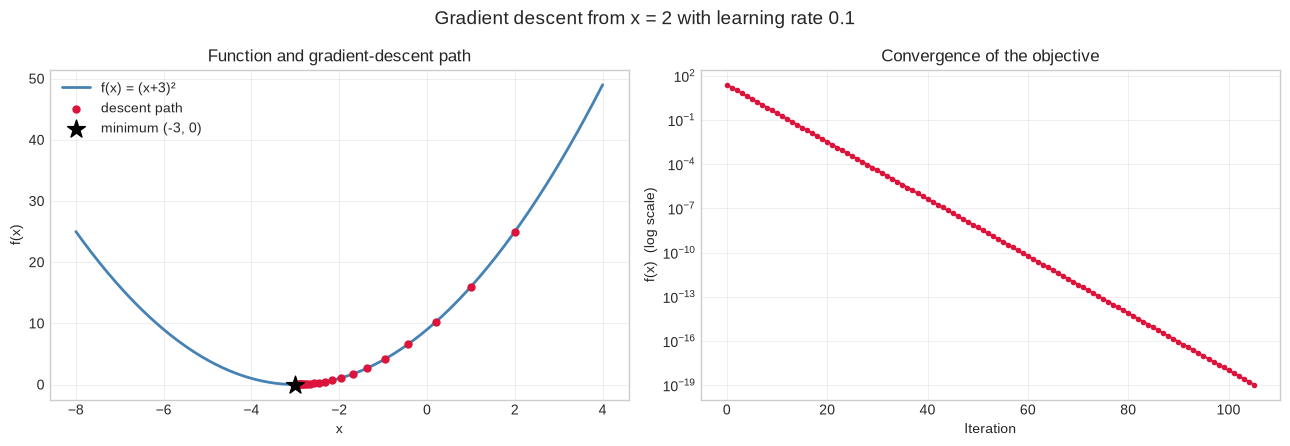

In [6]:
# Visualise the function and the descent path.
x_grid = np.linspace(-8, 4, 400)
path_x = [record["x"] for record in history]
path_y = [record["f(x)"] for record in history]

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(x_grid, f(x_grid), color="steelblue", linewidth=2, label="f(x) = (x+3)²")
axes[0].scatter(path_x, path_y, color="crimson", s=25, zorder=3, label="descent path")
axes[0].scatter([-3], [0], color="black", marker="*", s=180, zorder=4, label="minimum (-3, 0)")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].set_title("Function and gradient-descent path")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    [record["iteration"] for record in history],
    [record["f(x)"] for record in history],
    "o-",
    color="crimson",
    markersize=3,
)
axes[1].set_yscale("log")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("f(x)  (log scale)")
axes[1].set_title("Convergence of the objective")
axes[1].grid(alpha=0.3, which="both")

figure.suptitle("Gradient descent from x = 2 with learning rate 0.1", fontsize=14)
plt.tight_layout()
plt.show()

### 4.1 Effect of the learning rate

The theoretical analysis predicts:

| Learning rate | Behaviour |
|---|---|
| $0<\eta<0.5$ | Smooth convergence |
| $0.5<\eta<1$ | Oscillatory but convergent |
| $\eta=1$ | Permanent oscillation |
| $\eta>1$ | Divergence |

We now verify this experimentally.

In [7]:
learning_rates = [0.01, 0.05, 0.1, 0.3, 0.5, 0.8, 0.9, 1.0, 1.1]
rate_rows = []

for rate in learning_rates:
    final, run_history, run_status = gradient_descent(
        start=2.0, learning_rate=rate, max_iterations=500
    )
    rate_rows.append(
        {
            "learning rate": rate,
            "final x": final if abs(final) < 1e6 else np.inf,
            "final f(x)": f(final) if abs(final) < 1e6 else np.inf,
            "iterations": len(run_history) - 1,
            "status": run_status,
        }
    )

rate_table = pd.DataFrame(rate_rows)
# Avoid printing enormous divergent values in full.
rate_table["final x"] = rate_table["final x"].apply(
    lambda value: value if abs(value) < 1e6 else "diverged"
)
rate_table["final f(x)"] = rate_table["final f(x)"].apply(
    lambda value: value if abs(value) < 1e6 else "diverged"
)
rate_table

,learning rate,final x,final f(x),iterations,status
0,0.01,-2.999795,0.0,500,max iterations
1,0.05,-3.0,0.0,213,converged
2,0.10,-3.0,0.0,105,converged
3,0.30,-3.0,0.0,28,converged
4,0.50,-3.0,0.0,2,converged
5,0.80,-3.0,0.0,51,converged
6,0.90,-3.0,0.0,115,converged
7,1.00,2.0,25.0,500,oscillating
8,1.10,diverged,diverged,67,diverged


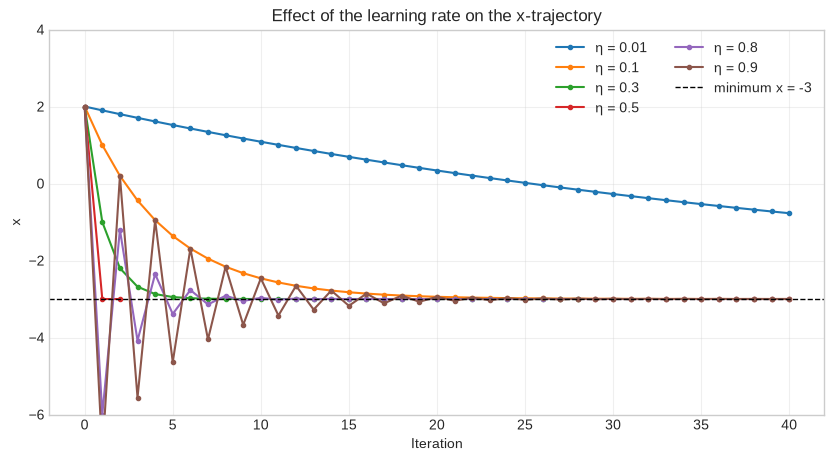

In [8]:
# Trajectories for selected learning rates.
selected_rates = [0.01, 0.1, 0.3, 0.5, 0.8, 0.9]
plt.figure(figsize=(10, 5))
for rate in selected_rates:
    _, run_history, _ = gradient_descent(
        start=2.0, learning_rate=rate, max_iterations=40
    )
    plt.plot(
        [record["iteration"] for record in run_history],
        [record["x"] for record in run_history],
        marker="o",
        markersize=3,
        label=f"η = {rate}",
    )

plt.axhline(-3, color="black", linestyle="--", linewidth=1, label="minimum x = -3")
plt.xlabel("Iteration")
plt.ylabel("x")
plt.title("Effect of the learning rate on the x-trajectory")
plt.ylim(-6, 4)
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.show()

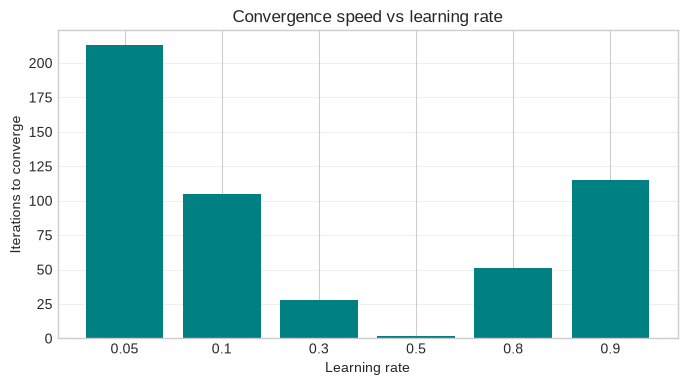

In [9]:
# Compare the number of iterations needed to reach the tolerance.
converged = rate_table[
    rate_table["status"] == "converged"
].sort_values("learning rate")

plt.figure(figsize=(8, 4))
plt.bar(
    converged["learning rate"].astype(str),
    converged["iterations"],
    color="teal",
)
plt.xlabel("Learning rate")
plt.ylabel("Iterations to converge")
plt.title("Convergence speed vs learning rate")
plt.grid(axis="y", alpha=0.3)
plt.show()

The best learning rate is not the largest one. A very small rate takes many
iterations; a rate near 1 oscillates or diverges. For this quadratic, the
error is multiplied by $|1-2\eta|$ each step, so the optimal rate is
$\eta=0.5$, which makes the error zero in one step. In practice, the best rate
depends on the curvature of the function and must be tuned.

In [10]:
# Different starting points: this convex function has the same minimum.
start_rows = []
for start in [-10, -5, 0, 2, 10]:
    final, run_history, run_status = gradient_descent(
        start=start, learning_rate=0.1
    )
    start_rows.append(
        {
            "start x": start,
            "final x": round(final, 8),
            "final f(x)": f"{f(final):.3e}",
            "iterations": len(run_history) - 1,
            "status": run_status,
        }
    )

pd.DataFrame(start_rows)

,start x,final x,final f(x),iterations,status
0,-10,-3.0,1.397e-19,106,converged
1,-5,-3.0,1.062e-19,101,converged
2,0,-3.0,1.530e-19,102,converged
3,2,-3.0,1.114e-19,105,converged
4,10,-3.0,1.263e-19,109,converged


In [11]:
# A non-convex example shows why the starting point can matter.
def g(x):
    return x**4 - 3 * x**2 + x


def g_gradient(x):
    return 4 * x**3 - 6 * x + 1


def gradient_descent_general(start, learning_rate=0.01, iterations=2_000):
    x = float(start)
    path = [x]
    for _ in range(iterations):
        x = x - learning_rate * g_gradient(x)
        path.append(x)
    return x, g(x), path


start_points = [-2.0, -1.0, 0.0, 1.0, 2.0]
nonconvex_rows = []
for start in start_points:
    final, value, _ = gradient_descent_general(start)
    nonconvex_rows.append(
        {"start x": start, "final x": round(final, 4), "g(final x)": round(value, 4)}
    )

print("Non-convex function g(x) = x^4 - 3x^2 + x")
display(pd.DataFrame(nonconvex_rows))

Non-convex function g(x) = x^4 - 3x^2 + x


,start x,final x,g(final x)
0,-2.0,-1.3008,-3.5139
1,-1.0,-1.3008,-3.5139
2,0.0,-1.3008,-3.5139
3,1.0,1.1309,-1.0702
4,2.0,1.1309,-1.0702


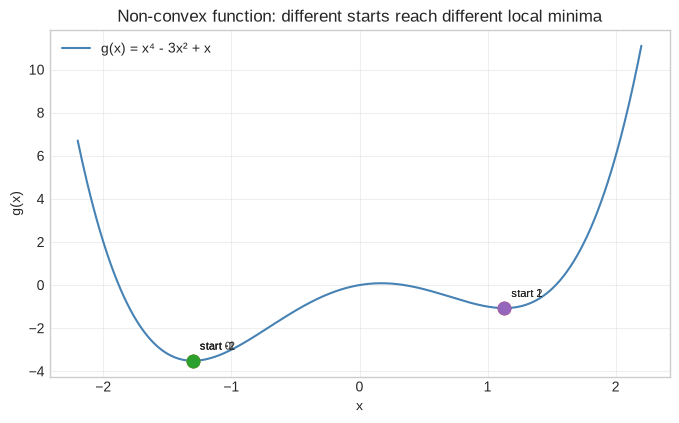

In [12]:
x_grid = np.linspace(-2.2, 2.2, 500)
plt.figure(figsize=(8, 4.5))
plt.plot(x_grid, g(x_grid), color="steelblue", label="g(x) = x⁴ - 3x² + x")
for start in start_points:
    _, _, path = gradient_descent_general(start)
    plt.scatter(path[-1], g(path[-1]), s=80, zorder=3)
    plt.annotate(f"start {start:g}", (path[-1], g(path[-1])), textcoords="offset points", xytext=(5, 8), fontsize=8)
plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("Non-convex function: different starts reach different local minima")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Test cases and validation

1. The default run converges to $x=-3$ with $f(x)=0$.
2. A learning rate of 0.01 does not reach the tolerance within 500
   iterations; 0.1 converges in about 100 iterations.
3. A learning rate of 1.0 oscillates; 1.1 diverges.
4. A non-positive learning rate is rejected.
5. Different starting points reach the same minimum for the convex quadratic.

In [13]:
# Validation checks.
for bad_rate in [0, -0.1]:
    try:
        gradient_descent(learning_rate=bad_rate)
    except ValueError as error:
        print(f"ValueError for η={bad_rate}: {error}")

try:
    gradient_descent(max_iterations=0)
except ValueError as error:
    print(f"ValueError for max_iterations=0: {error}")

assert abs(final_x - (-3)) < 1e-6
assert status == "converged"
print("\nDefault run reached x = -3 ✓")

ValueError for η=0: learning_rate must be positive
ValueError for η=-0.1: learning_rate must be positive
ValueError for max_iterations=0: max_iterations must be at least 1

Default run reached x = -3 ✓


In [14]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - ML Practical 4 (Gradient descent)")
print("=" * 78)
print(
    "The objective is f(x)=(x+3)^2, whose exact minimum is x=-3 with f(x)=0.\n"
    "The gradient is 2(x+3). The report shows the descent path, the update\n"
    "rule, the effect of the learning rate and the non-convex example."
)

print("\n1. DEFAULT RUN: START x=2, LEARNING RATE 0.1")
print("-" * 78)
print(f"Final x             : {final_x:.12f}")
print(f"Final f(x)          : {f(final_x):.3e}")
print(f"Analytical minimum  : x=-3, f(x)=0")
print(f"Absolute error      : {abs(final_x + 3):.3e}")
print(f"Iterations          : {len(history) - 1}")
print(f"Status              : {status}")
print("The update is x_new = x - eta * 2(x+3). With eta=0.1, the error from")
print("the minimum is multiplied by |1 - 2*eta| = 0.8 on every iteration, so the")
print("sequence approaches -3 geometrically. Convergence is declared when the")
print("change in x is smaller than the tolerance (1e-10).")

print("\n2. FIRST ITERATIONS")
print("-" * 78)
for record in history[:6]:
    step_text = "n/a" if record["step"] is None else f"{record['step']:.6f}"
    print(
        f"  t={record['iteration']:2d}: x={record['x']: .6f}, "
        f"f(x)={record['f(x)']: .6f}, gradient={record['gradient']: .6f}, "
        f"step={step_text}"
    )
print("At x=2 the gradient is +10, so a step of eta*10=1 moves left to x=1.")
print("As x approaches -3, the gradient shrinks and the steps become smaller.")
print("This is why the objective decreases quickly at first and then flattens.")

print("\n3. EFFECT OF THE LEARNING RATE")
print("-" * 78)
for _, row in rate_table.iterrows():
    print(
        f"  eta={row['learning rate']:.2f}: status={row['status']:16s}, "
        f"iterations={int(row['iterations'])}"
    )
converged_rates = rate_table[rate_table["status"] == "converged"].sort_values("iterations")
if len(converged_rates):
    fastest = converged_rates.iloc[0]
    print(
        f"Fastest converging rate in this table: eta={fastest['learning rate']:.2f} "
        f"with {int(fastest['iterations'])} iterations"
    )
print("Theory: the error factor is |1-2*eta|.")
print("  0 < eta < 0.5 : monotone convergence (factor between 1 and 0)")
print("  0.5 < eta < 1 : oscillatory convergence (factor between 0 and 1,")
print("                  but its sign alternates)")
print("  eta = 1       : permanent oscillation; the error does not shrink")
print("  eta > 1       : divergence; the error grows")
print("A very small rate is stable but slow. A rate near 1 is fast in theory but")
print("oscillates, and a rate above 1 overshoots and diverges.")

print("\n4. DIFFERENT STARTING POINTS ON THE CONVEX QUADRATIC")
print("-" * 78)
start_table = pd.DataFrame(start_rows)
for _, row in start_table.iterrows():
    print(
        f"  start={row['start x']:5.1f}: final x={row['final x']: .8f}, "
        f"f(x)={row['final f(x)']}, iterations={int(row['iterations'])}, "
        f"status={row['status']}"
    )
print("For a convex function every start reaches the same global minimum. The")
print("number of iterations differs because the initial distance from -3")
print("differs, but the limit is identical.")

print("\n5. NON-CONVEX FUNCTION g(x)=x^4-3x^2+x")
print("-" * 78)
nonconvex_table = pd.DataFrame(nonconvex_rows)
for _, row in nonconvex_table.iterrows():
    print(
        f"  start={row['start x']:5.1f}: final x={row['final x']: .4f}, "
        f"g(final)={row['g(final x)']: .4f}"
    )
print("The non-convex function has more than one local minimum. Negative starts")
print("and positive starts can end in different basins, so the final point")
print("depends on initialisation. This is why random restarts and good weight")
print("initialisation matter in neural networks.")

print("\n6. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Each iteration evaluates one gradient and updates one scalar: O(1).")
print("Total time is O(k) for k iterations; storing the full history is O(k).")
print("In a neural network with p parameters and n examples, one full-batch")
print("gradient costs O(np); a mini-batch of size b costs O(bp) per step.")
print("The convergence rate depends on the curvature and the learning rate, not")
print("only on the number of iterations.")

DETAILED OUTPUT EXPLANATION - ML Practical 4 (Gradient descent)
The objective is f(x)=(x+3)^2, whose exact minimum is x=-3 with f(x)=0.
The gradient is 2(x+3). The report shows the descent path, the update
rule, the effect of the learning rate and the non-convex example.

1. DEFAULT RUN: START x=2, LEARNING RATE 0.1
------------------------------------------------------------------------------
Final x             : -2.999999999666
Final f(x)          : 1.114e-19
Analytical minimum  : x=-3, f(x)=0
Absolute error      : 3.337e-10
Iterations          : 105
Status              : converged
The update is x_new = x - eta * 2(x+3). With eta=0.1, the error from
the minimum is multiplied by |1 - 2*eta| = 0.8 on every iteration, so the
sequence approaches -3 geometrically. Convergence is declared when the
change in x is smaller than the tolerance (1e-10).

2. FIRST ITERATIONS
------------------------------------------------------------------------------
  t= 0: x= 2.000000, f(x)= 25.000000, gradi

### Observations

1. Gradient descent follows the negative gradient and converges to the
   minimiser $x=-3$.
2. The learning rate controls the step size. Too small a value wastes
   iterations; too large a value overshoots, oscillates or diverges.
3. For this quadratic, convergence is guaranteed exactly when
   $0<\eta<1$, matching the factor $|1-2\eta|$ derived above.
4. The function is convex, so every starting point reaches the same global
   minimum.
5. For a non-convex function, different starts can end at different local
   minima. This is why initialisation matters in neural networks.

### Complexity analysis

- Each iteration: one gradient evaluation, $O(1)$ for this scalar function.
- Total time: $O(k)$ for $k$ iterations.
- Space: $O(1)$ if only the current point is stored; $O(k)$ if the full
  history is kept for plotting.
- In a neural network with $p$ parameters and $n$ examples, one full-batch
  gradient costs $O(np)$; mini-batch SGD costs $O(bp)$ per step for batch size
  $b$.

## 5. Conclusion

We implemented gradient descent for $f(x)=(x+3)^2$ and verified that it
converges to the analytical minimum $x=-3$, $f(x)=0$. The experiment shows the
critical role of the learning rate: values below 1 converge (smoothly or with
oscillations), $\eta=1$ oscillates forever, and $\eta>1$ diverges. The
non-convex example demonstrates that gradient descent finds a local minimum,
which need not be the global one.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is gradient descent? | An iterative optimisation method that moves opposite to the gradient. |
| What is the update rule? | $x_{t+1}=x_t-\eta\nabla f(x_t)$. |
| What does the learning rate control? | The size of each step. |
| What happens if the learning rate is too large? | The method overshoots, oscillates or diverges. |
| What happens if it is too small? | Convergence is very slow. |
| When does this quadratic converge? | For $0<\eta<1$; the error is multiplied by $1-2\eta$. |
| What is a local minimum? | A point lower than its immediate neighbours but not necessarily the global lowest point. |
| Why does the starting point matter? | For non-convex functions, different starts can lead to different local minima. |
| What is the difference between batch and stochastic gradient descent? | Batch uses the full dataset for each gradient; stochastic uses one sample (or a mini-batch). |